# Image patching

Load an RGB image and resize it to the experiment's resolution. The patch extractor only rearranges pixels; normalization happens in the image-loading cell. Choose image dimensions divisible by the patch size.

image tensor shape: torch.Size([1, 3, 224, 224])
patches tensor shape: torch.Size([1, 196, 768])


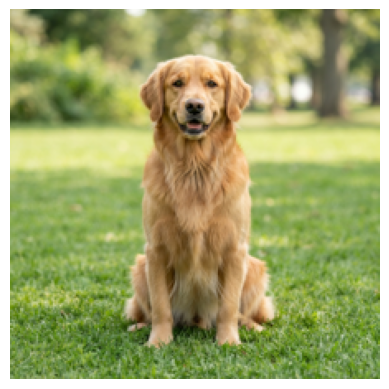

In [12]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import torch

from models.patch_embedding import patchify, PatchEmbeddingModel

torch.manual_seed(0)
np.random.seed(0)

image_size = 224
patch_size = 16
hidden_dim = 192

image = Image.open("data/image_8765cd2c.jpg").convert("RGB").resize((image_size, image_size))

image_tensor = torch.from_numpy(np.array(image)).permute(2, 0, 1).unsqueeze(0).float() / 255.0
results = patchify(image_tensor, patch_size=patch_size)
patches = results["patches"]

print(f"image tensor shape: {image_tensor.shape}")
print(f"patches tensor shape: {patches.shape}")
plt.imshow(image)
plt.axis("off")
plt.show()

# Patch projection, classification token, and learned positions

Create the model once and reuse it. It owns the linear projection, the shared classification token, and one learned position vector per token (including [CLS]). The returned patch embeddings are the raw projection; the complete token sequence also includes [CLS] and positions.

For 224 × 224 RGB images and 16 × 16 patches: [B, 3, 224, 224] → [B, 196, 768] → [B, 196, 192] → [B, 197, 192].

In [13]:
patch_embedder = PatchEmbeddingModel(
    embedding_dim=results["embedding_dim"],
    hidden_dim=hidden_dim,
    num_patches=patches.size(1),
)
embedded_patches = patch_embedder(patches)

print(f"projected patches: {embedded_patches['embedded_patches'].shape}")
print(f"encoder input ([CLS] + patches + positions): {embedded_patches['patches_with_cls_token'].shape}")
print(f"shared classification parameter: {embedded_patches['cls_token'].shape}")
print(f"learned positions: {embedded_patches['positional_encoding'].shape}")

projected patches: torch.Size([1, 196, 192])
encoder input ([CLS] + patches + positions): torch.Size([1, 197, 192])
shared classification parameter: torch.Size([1, 1, 192])
learned positions: torch.Size([1, 197, 192])


# Transformer encoder

Build one encoder block with token width 192, three attention heads, and an MLP width of 768 (four times the token width). Each head has width 64. This is a shallow ViT for learning, not one of the original paper's depth configurations.

The ViT block normalizes before each sublayer: input → LayerNorm → attention → residual addition → LayerNorm → MLP → residual addition. The residual paths bypass normalization. Apply a final LayerNorm after the encoder; if we later add more blocks, it still belongs after the whole stack.

In [14]:
from models.transformer_encoder import TransformerEncoderLayer

transformer_encoder = TransformerEncoderLayer(hidden_dim=hidden_dim, num_heads=3, feedforward_dim=hidden_dim * 4, dropout=0.1)
encoder_norm = torch.nn.LayerNorm(hidden_dim)

# The classification MLP head

Select the final normalized [CLS] representation and map it to ten class logits: [B, 192] → [B, 768] → [B, 10]. The hidden width is an experiment choice. We keep the GELU activation you implemented; the original ViT implementation used tanh in its optional hidden classification layer.

The head returns raw logits. Cross-entropy handles their conversion to log probabilities internally. Use softmax separately to display probabilities; do not feed those probabilities into cross-entropy.

References: [original ViT, §3.1 and Eq. 4](https://arxiv.org/html/2010.11929v2#S3.SS1), [official classification head](https://github.com/google-research/vision_transformer/blob/main/vit_jax/models_vit.py), [PyTorch cross-entropy](https://docs.pytorch.org/docs/2.15/generated/torch.nn.CrossEntropyLoss.html).

In [15]:
from models.mlp_head import MLPHead

mlp_head = MLPHead(input_dim=hidden_dim, hidden_dim=hidden_dim * 4, output_dim=10)

# Gradient flow through the classification model

This runs the complete path: patch projection → [CLS] and positions → encoder → final LayerNorm → [CLS] selection → classification head → cross-entropy. The target below is an arbitrary demonstration label, not a label inferred from the photo. Backpropagation shows connectivity; no optimizer step or training occurs here.

We report each parameter's L2 gradient norm and RMS (norm divided by the square root of its element count). Each component's combined norm, and the full-model norm, are the square root of the sum of the corresponding squared parameter norms. RMS helps account for tensor size; these values still do not rank component importance.

Key-bias gradients can be zero because their common offset cancels in attention softmax. Gradient magnitudes depend on the image, target, initialization, dropout, and loss; there is no universal good value.

In [16]:
model_components = (
    ("patch_embedder", patch_embedder),
    ("transformer_encoder", transformer_encoder),
    ("encoder_norm", encoder_norm),
    ("mlp_head", mlp_head),
)
for _, component in model_components:
    component.train()
    component.zero_grad()

embedding_outputs = patch_embedder(patches)
encoder_inputs = embedding_outputs["patches_with_cls_token"]
encoded_tokens = transformer_encoder(encoder_inputs)
normalized_tokens = encoder_norm(encoded_tokens)
cls_representation = normalized_tokens[:, 0, :]
classification_logits = mlp_head(cls_representation)
classification_probabilities = classification_logits.detach().softmax(dim=-1)

print(f"encoder input: {encoder_inputs.shape}")
print(f"encoder output: {encoded_tokens.shape}")
print(f"normalized classification-token representation: {cls_representation.shape}")
print(f"classification logits: {classification_logits.shape}")
print(f"display probabilities sum: {classification_probabilities.sum(dim=-1)}")

# Placeholder class 0: this only demonstrates the classification gradient path.
# Replace it with real labels for a training experiment.
demo_targets = torch.zeros(patches.size(0), dtype=torch.long, device=patches.device)
loss = torch.nn.functional.cross_entropy(classification_logits, demo_targets)
loss.backward()
print(f"demonstration cross-entropy loss: {loss.item():.6f}")

component_norms = []
for component_name, component in model_components:
    parameter_norms = []
    for name, parameter in component.named_parameters():
        gradient_norm = parameter.grad.norm()
        gradient_rms = gradient_norm / (parameter.numel() ** 0.5)
        parameter_norms.append(gradient_norm)
        print(f"{component_name}.{name}: shape={tuple(parameter.shape)}, "
              f"gradient norm={gradient_norm.item():.6f}, RMS={gradient_rms.item():.6f}")
    component_norm = torch.stack(parameter_norms).norm()
    component_norms.append(component_norm)
    print(f"{component_name} combined gradient norm: {component_norm.item():.6f}")

full_gradient_norm = torch.stack(component_norms).norm()
print(f"full model gradient norm: {full_gradient_norm.item():.6f}")

encoder input: torch.Size([1, 197, 192])
encoder output: torch.Size([1, 197, 192])
normalized classification-token representation: torch.Size([1, 192])
classification logits: torch.Size([1, 10])
display probabilities sum: tensor([1.0000])
demonstration cross-entropy loss: 2.294088
patch_embedder.cls_token: shape=(1, 1, 192), gradient norm=0.510495, RMS=0.036842
patch_embedder.embedder.weight: shape=(192, 768), gradient norm=7.768571, RMS=0.020231
patch_embedder.embedder.bias: shape=(192,), gradient norm=0.550426, RMS=0.039724
patch_embedder.positional_encoding.pe: shape=(1, 197, 192), gradient norm=0.512106, RMS=0.002633
patch_embedder combined gradient norm: 7.821542
transformer_encoder.self_attention.heads.0.query.weight: shape=(64, 192), gradient norm=0.015625, RMS=0.000141
transformer_encoder.self_attention.heads.0.query.bias: shape=(64,), gradient norm=0.001143, RMS=0.000143
transformer_encoder.self_attention.heads.0.key.weight: shape=(64, 192), gradient norm=0.014798, RMS=0.00013

# Experiments

Use Imagenette for three small experiments:
- Memorize 20 training images to check that the model can learn.
- Vary patch size and attention heads to inspect their effect on performance and timing.
- Compare a custom small ViT and half-width ResNet-18 trained from scratch on the same splits.


## Memorization and functionality

Use two training images per class (20 total), with fixed 224 × 224 preprocessing. Both loaders read the same images; validation here measures memorization with dropout disabled, not held-out performance.

Part 1 uses its original `linear_scheduler`: validation-driven learning-rate reductions, with no warmup. Start at the supplied learning rate and halve it after four epochs without a validation-loss improvement greater than 0.001. Step the scheduler once after each validation epoch.

Early stopping remains enabled: stop after ten epochs without a validation-accuracy gain greater than 0.001, counting from the first epoch. The configured number of epochs is only a maximum; Part 1 is not forced to complete it. The learning-rate history records the rate at the start of each epoch.

Checkpoints track the highest validation accuracy, retaining the earlier checkpoint on ties. Training restores those weights before returning. Training and evaluation outputs affected by the scheduler cleanup have been cleared; rerun the selected experiment cells for current results.

Each model saves one `.pth` file containing its weights, model name/configuration, selected epoch, validation loss, and validation accuracy. Epoch curves stay in the returned `history` dictionary. The scaling and CNN experiments each write one compact `results.json`.


In [17]:
from datasets.imagenette import download_imagenette_dataset
from torch.utils.data import DataLoader, Subset

batch_size = 32
samples_per_class = 2

imagenette_train_dataset = download_imagenette_dataset(split="train", image_size=image_size)

class_indices = np.array([label for _, label in imagenette_train_dataset._samples])
rng = np.random.default_rng(0)
memorization_indices = np.concatenate([
    rng.choice(np.flatnonzero(class_indices == label), samples_per_class, replace=False)
    for label in range(len(imagenette_train_dataset.classes))
]).tolist()
memorization_dataset = Subset(imagenette_train_dataset, memorization_indices)

train_loader = DataLoader(memorization_dataset, batch_size=batch_size, shuffle=True)
validation_loader = DataLoader(memorization_dataset, batch_size=batch_size, shuffle=False)

print(f"Memorization examples: {len(memorization_dataset)}")
print(f"Examples per class: {np.bincount(class_indices[memorization_indices]).tolist()}")

Memorization examples: 20
Examples per class: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


In [18]:
from datetime import datetime
from pathlib import Path
from models.vision_transformer import build_vision_transformer
from pipeline.part1_train import train_model

checkpoint_root = Path("artifacts") / datetime.now().strftime("%Y%m%d_%H%M%S")
memorization_checkpoint = checkpoint_root / "memorization" / "vit.pth"
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Checkpoint: {memorization_checkpoint}; device: {device}")

torch.manual_seed(0)
model = build_vision_transformer(
    image_size=image_size, patch_size=patch_size, hidden_dim=hidden_dim,
    num_heads=3, num_layers=1, mlp_ratio=4, num_classes=10, dropout=0.1,
)
history = train_model(
    model, train_loader, validation_loader,
    early_stopping_patience=10,
    num_epochs=100, learning_rate=0.0005, device=device,
    checkpoint_path=memorization_checkpoint,
)


Checkpoint: artifacts/20261111_000754/memorization/vit.pth; device: mps
Epoch 1/100: train loss=2.3396, val loss=2.2712, val accuracy=0.1000, lr=0.0005, train=0.36s, val=0.02s
Epoch 2/100: train loss=2.2606, val loss=2.2267, val accuracy=0.2000, lr=0.0005, train=0.03s, val=0.02s
Epoch 3/100: train loss=2.2382, val loss=2.1817, val accuracy=0.2000, lr=0.0005, train=0.03s, val=0.02s
Epoch 4/100: train loss=2.1810, val loss=2.1180, val accuracy=0.2500, lr=0.0005, train=0.03s, val=0.02s
Epoch 5/100: train loss=2.1520, val loss=2.0232, val accuracy=0.3000, lr=0.0005, train=0.03s, val=0.02s
Epoch 6/100: train loss=2.0569, val loss=1.9154, val accuracy=0.3500, lr=0.0005, train=0.02s, val=0.02s
Epoch 7/100: train loss=1.9344, val loss=1.7750, val accuracy=0.3500, lr=0.0005, train=0.03s, val=0.02s
Epoch 8/100: train loss=1.8439, val loss=1.6524, val accuracy=0.3500, lr=0.0005, train=0.03s, val=0.02s
Epoch 9/100: train loss=1.6980, val loss=1.5871, val accuracy=0.4500, lr=0.0005, train=0.03s, va

In [19]:
from pipeline.evaluate import evaluate_model

memorization_metrics = evaluate_model(
    model, validation_loader, device, checkpoint_path=memorization_checkpoint,
)
print("Metrics on the SAME training images, using the highest-validation-accuracy checkpoint:")
for metric_name in ("accuracy", "precision", "recall", "f1_score"):
    print(f"{metric_name}: {memorization_metrics[metric_name]:.4f}")
print(f"Evaluation time: {memorization_metrics['evaluation_seconds']:.3f}s")
print("Confusion matrix (rows = targets, columns = predictions):")
print(memorization_metrics["confusion_matrix"])


Metrics on the SAME training images, using the highest-validation-accuracy checkpoint:
accuracy: 1.0000
precision: 1.0000
recall: 1.0000
f1_score: 1.0000
Evaluation time: 0.026s
Confusion matrix (rows = targets, columns = predictions):
[[2 0 0 0 0 0 0 0 0 0]
 [0 2 0 0 0 0 0 0 0 0]
 [0 0 2 0 0 0 0 0 0 0]
 [0 0 0 2 0 0 0 0 0 0]
 [0 0 0 0 2 0 0 0 0 0]
 [0 0 0 0 0 2 0 0 0 0]
 [0 0 0 0 0 0 2 0 0 0]
 [0 0 0 0 0 0 0 2 0 0]
 [0 0 0 0 0 0 0 0 2 0]
 [0 0 0 0 0 0 0 0 0 2]]


## Attention scaling

Run the dataset/split cell and then the sweep below; the memorization run can be skipped. Vary patch size (8, 16, 32) and heads (1, 2, 3, 4), keeping image size 224, token width 192, one encoder block, MLP width 768, dropout, starting learning rate, and one seed fixed.

Split the official training images into stratified 80% training and 20% internal validation subsets. The official validation split is reserved for testing and is not evaluated during this sweep.

Each configuration uses the epoch budget set by `scaling_epochs` below, with the original validation-driven scheduler and early stopping as described above. Save each model's highest-validation-accuracy weights and report loss at that checkpoint, actual epochs run, average training/validation seconds per epoch, and inference latency. The sweep preserves the original selection rule: lowest validation loss among the saved checkpoints, retaining the earlier configuration on ties. Epoch curves remain in `scaling_histories` for plotting.

Timing covers the complete ViT, including patch embedding and the classification head. Epoch times include data loading and transfers. Inference uses one fixed validation batch, five warmups, and the median of twenty timed forwards; device synchronization waits for those forwards to finish, while loading and transfers remain outside that timer.

At fixed width 192, more heads means narrower heads (192, 96, 64, 48). Attention score storage, softmax, and sequential head calls can still change latency. Patch size changes token count, projection size, and learned-position parameters, so also record token and parameter counts.

Files: one `.pth` per patch/head configuration and one `results.json` for the whole sweep, in the printed run folder.


In [20]:
import numpy as np
import torch
from datasets.imagenette import download_imagenette_dataset
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

image_size = 224
batch_size = 32
split_seed = 0

imagenette_training_pool = download_imagenette_dataset(split="train", image_size=image_size)
imagenette_test_dataset = download_imagenette_dataset(split="val", image_size=image_size)
pool_labels = np.array([label for _, label in imagenette_training_pool._samples])

# Split indices rather than materializing thousands of transformed image tensors.
train_indices, validation_indices = train_test_split(
    np.arange(len(imagenette_training_pool)),
    test_size=0.2,
    stratify=pool_labels,
    random_state=split_seed,
)
imagenette_train_dataset = Subset(imagenette_training_pool, train_indices.tolist())
imagenette_validation_dataset = Subset(imagenette_training_pool, validation_indices.tolist())

train_loader = DataLoader(
    imagenette_train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=torch.Generator().manual_seed(split_seed),
)
validation_loader = DataLoader(imagenette_validation_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(imagenette_test_dataset, batch_size=batch_size, shuffle=False)

print(f"Training images: {len(imagenette_train_dataset)}")
print(f"Internal validation images: {len(imagenette_validation_dataset)}")
print(f"Reserved test images (official val split): {len(imagenette_test_dataset)}")

Training images: 7575
Internal validation images: 1894
Reserved test images (official val split): 3925


In [24]:
from datetime import datetime
from pathlib import Path
from pipeline.part1_train import train_model
from pipeline.checkpoints import save_results
from pipeline.inference import measure_inference_ms
from models.vision_transformer import build_vision_transformer

scaling_dir = Path("artifacts") / datetime.now().strftime("%Y%m%d_%H%M%S") / "attention_scaling"
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Checkpoints and results: {scaling_dir}; device: {device}")

patch_sizes = (8, 16, 32)
attention_heads = (1, 2, 3, 4)
scaling_epochs = 1
scaling_seed = 0
hidden_dim = 192
scaling_results = []
scaling_histories = {}
inference_images, _ = next(iter(validation_loader))
inference_images = inference_images.to(device)

for scaling_patch_size in patch_sizes:
    for num_heads in attention_heads:
        torch.manual_seed(scaling_seed)
        train_loader.generator.manual_seed(scaling_seed)
        print(f"Patch size: {scaling_patch_size}, heads: {num_heads}")
        scaling_model = build_vision_transformer(
            image_size=image_size, patch_size=scaling_patch_size,
            hidden_dim=hidden_dim, num_heads=num_heads, num_layers=1,
            mlp_ratio=4, num_classes=10, dropout=0.1,
        )
        scaling_history = train_model(
            scaling_model, train_loader, validation_loader,
            early_stopping_patience=10,
            num_epochs=scaling_epochs, learning_rate=0.0005, device=device,
            checkpoint_path=scaling_dir / f"vit_p{scaling_patch_size}_h{num_heads}.pth",
            min_delta=0.001
        )
        epochs_run = len(scaling_history["train_loss"])
        row = {
            "patch_size": scaling_patch_size, "heads": num_heads,
            "tokens": (image_size // scaling_patch_size) ** 2 + 1,
            "parameters": sum(p.numel() for p in scaling_model.parameters()),
            "epochs_run": epochs_run,
            "best_epoch": scaling_history["best_epoch"],
            "validation_loss": scaling_history["val_loss_at_best_accuracy"],
            "validation_accuracy": scaling_history["best_val_accuracy"],
            "mean_train_seconds_per_epoch": sum(scaling_history["train_seconds"]) / epochs_run,
            "mean_validation_seconds_per_epoch": sum(scaling_history["validation_seconds"]) / epochs_run,
            "median_inference_ms_per_batch": measure_inference_ms(scaling_model, inference_images, device),
        }
        scaling_results.append(row)
        scaling_histories[(scaling_patch_size, num_heads)] = scaling_history
        print(row)
        scaling_model.cpu()

selected_scaling_result = min(scaling_results, key=lambda row: row["validation_loss"])
print("Lowest-validation-loss configuration:",
      {name: selected_scaling_result[name] for name in ("patch_size", "heads")})
save_results(scaling_results, scaling_dir / "results.json")


Checkpoints and results: artifacts/20261111_001216/attention_scaling; device: mps
Patch size: 8, heads: 1
Epoch 1/1: train loss=2.1827, val loss=2.0479, val accuracy=0.2503, lr=0.0005, train=16.68s, val=3.38s
Restored epoch 1 (highest validation accuracy=0.2503)
{'patch_size': 8, 'heads': 1, 'tokens': 785, 'parameters': 789130, 'epochs_run': 1, 'best_epoch': 1, 'validation_loss': 2.047901591630269, 'validation_accuracy': 0.2502639915522703, 'mean_train_seconds_per_epoch': 16.68425400002161, 'mean_validation_seconds_per_epoch': 3.384517792001134, 'median_inference_ms_per_batch': 15.690771004301496}
Patch size: 8, heads: 2
Epoch 1/1: train loss=2.1320, val loss=1.9572, val accuracy=0.3168, lr=0.0005, train=17.31s, val=2.84s
Restored epoch 1 (highest validation accuracy=0.3168)
{'patch_size': 8, 'heads': 2, 'tokens': 785, 'parameters': 789130, 'epochs_run': 1, 'best_epoch': 1, 'validation_loss': 1.9571704105439633, 'validation_accuracy': 0.3167898627243928, 'mean_train_seconds_per_epoch':

## Comparison with a CNN

Run the dataset/split cell above, then this comparison. The memorization and scaling runs can be skipped.

| Model | Configuration | Parameters |
| --- | --- | ---: |
| Custom half-width ResNet-18 | Basic blocks [2, 2, 2, 2]; widths 32, 64, 128, 256 | 2,801,450 |
| Custom ViT | Six blocks; width 192; four heads; MLP width 768; patch size 16 | 3,011,146 |

The ViT has 7.5% more parameters. Both start from scratch with the same 224 × 224 inputs, splits, batch size 32, seed, AdamW learning rate 0.0005, weight decay 0.01, and the epoch budget set by `comparison_epochs` below. Both use the same original validation-driven scheduler and early stopping; report the actual epochs each runs. Similar parameter counts do not equalize computation or optimization difficulty.

The ViT reuses our pre-normalized encoder block with independent weights in all six blocks and a final LayerNorm after the stack. The earlier one-block ViT remains the scaling configuration.

Finish both training runs before evaluating either held-out test score. Evaluation reloads each highest-validation-accuracy checkpoint. Report accuracy, loss, training/validation/test time, and inference latency on the same validation batch.

Files: one `.pth` for each model and one `results.json` for the comparison. Epoch curves remain in `comparison_histories`.


In [ ]:
from datetime import datetime
from pathlib import Path
from pipeline.part1_train import train_model
from pipeline.evaluate import evaluate_model
from pipeline.checkpoints import save_results
from models.resnet18 import ResNet18
from models.vision_transformer import build_vision_transformer
from pipeline.inference import measure_inference_ms

comparison_dir = Path("artifacts") / datetime.now().strftime("%Y%m%d_%H%M%S") / "comparison"
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Checkpoints and results: {comparison_dir}; device: {device}")

comparison_seed = 0
comparison_epochs = 100
comparison_model_names = ("resnet18_half_width", "vit_d192_l6")
comparison_models = {}
comparison_histories = {}
comparison_results = {}
comparison_inference_images, _ = next(iter(validation_loader))
comparison_inference_images = comparison_inference_images.to(device)

# Train both before reading either model's held-out test result.
for model_name in comparison_model_names:
    torch.manual_seed(comparison_seed)
    train_loader.generator.manual_seed(comparison_seed)
    if model_name == "resnet18_half_width":
        comparison_model = ResNet18(num_classes=10, base_channels=32)
    else:
        comparison_model = build_vision_transformer(
            image_size=image_size, patch_size=16, hidden_dim=192,
            num_heads=4, num_layers=6, mlp_ratio=4, num_classes=10, dropout=0.1,
        )
    print(model_name)
    comparison_histories[model_name] = train_model(
        comparison_model, train_loader, validation_loader,
        early_stopping_patience=10,
        num_epochs=comparison_epochs, learning_rate=0.0005, weight_decay=0.01,
        device=device, checkpoint_path=comparison_dir / f"{model_name}.pth", 
        min_delta=0.001
    )
    comparison_models[model_name] = comparison_model.cpu()

for model_name in comparison_model_names:
    comparison_model = comparison_models[model_name]
    test_metrics = evaluate_model(
        comparison_model, test_loader, device,
        checkpoint_path=comparison_dir / f"{model_name}.pth",
    )
    fit_history = comparison_histories[model_name]
    comparison_results[model_name] = {
        "parameters": sum(p.numel() for p in comparison_model.parameters()),
        "epochs_run": len(fit_history["train_loss"]),
        "best_epoch": fit_history["best_epoch"],
        "validation_loss": fit_history["val_loss_at_best_accuracy"],
        "validation_accuracy": fit_history["best_val_accuracy"],
        "test_accuracy": test_metrics["accuracy"], "test_loss": test_metrics["loss"],
        "training_seconds": sum(fit_history["train_seconds"]),
        "validation_seconds": sum(fit_history["validation_seconds"]),
        "test_evaluation_seconds": test_metrics["evaluation_seconds"],
        "median_inference_ms_per_batch": measure_inference_ms(comparison_model, comparison_inference_images, device),
    }
    print(model_name, comparison_results[model_name])
    comparison_model.cpu()

save_results(comparison_results, comparison_dir / "results.json")


Checkpoints and results: artifacts/20261111_001102/comparison; device: mps
resnet18_half_width
Epoch 1/1: train loss=1.6031, val loss=2.6798, val accuracy=0.2835, lr=0.0005, train=14.16s, val=2.42s
Restored epoch 1 (highest validation accuracy=0.2835)
vit_d192_l6
Epoch 1/1: train loss=2.2388, val loss=2.1596, val accuracy=0.2012, lr=0.0005, train=18.15s, val=2.64s
Restored epoch 1 (highest validation accuracy=0.2012)
resnet18_half_width {'parameters': 2801450, 'epochs_run': 1, 'best_epoch': 1, 'validation_loss': 2.679778446995092, 'validation_accuracy': 0.28352692713833155, 'test_accuracy': 0.2692993630573248, 'test_loss': 2.679134151252212, 'training_seconds': 14.164158708998002, 'validation_seconds': 2.4164224159903824, 'test_evaluation_seconds': 6.478078000014648, 'median_inference_ms_per_batch': 7.685832999413833}
vit_d192_l6 {'parameters': 3011146, 'epochs_run': 1, 'best_epoch': 1, 'validation_loss': 2.159572426847319, 'validation_accuracy': 0.20116156282998943, 'test_accuracy': 0